# Practice Notebook 3.3: Two-Way ANOVA and Interactions

Advanced Statistics Course, Brain Science, Period 2 (Week 3 practice)

This notebook focuses on the **two-way between-subjects ANOVA**: degrees of freedom, partitioning the variance into two main effects, an interaction and error, and above all **interpreting interactions** correctly.
You'll start with paper-and-pencil exercises and then analyse a 3 × 2 audiovisual detection experiment in Python.

Please note: paper-and-pencil questions are followed directly by an **Answer** cell. For coding tasks, first work in the empty task cell(s), then compare with the **Solution** cell(s) below them.

In [ ]:
# Before running the analyses, we need to install a few Python libraries.
# Run the following command in your terminal or Jupyter Notebook (only needed once):
%pip install pandas numpy scipy matplotlib seaborn pingouin statsmodels

### Part 1: Degrees of freedom (paper and pencil)

1. The experiment analysed in Part 3 has Factor A = **background noise** (3 levels) and Factor B = **target modality** (2 levels), with 8 participants per cell. Give $N$ and the df for A, B, A × B, error and total.
2. A different study crosses **4 stimulus contrasts** with **3 viewing distances**, 5 participants per cell. Give $N$ and all df.
3. In both designs, which mean square is the denominator of **every** F-ratio, and what does it represent?

**Answer**

1. $N = 3 \cdot 2 \cdot 8 = 48$
   - $df_A = a - 1 = 2$, $df_B = b - 1 = 1$, $df_{A \times B} = (a-1)(b-1) = 2$
   - $df_E = N - ab = 48 - 6 = 42$, $df_T = N - 1 = 47$
   - Check: $2 + 1 + 2 + 42 = 47$ ✓
2. $N = 4 \cdot 3 \cdot 5 = 60$
   - $df_A = 3$, $df_B = 2$, $df_{A \times B} = 3 \cdot 2 = 6$, $df_E = 60 - 12 = 48$, $df_T = 59$ ($3 + 2 + 6 + 48 = 59$ ✓)
3. $MS_E$ (error, within-cell mean square): $F_A = MS_A / MS_E$, $F_B = MS_B / MS_E$, $F_{A \times B} = MS_{A \times B} / MS_E$. $MS_E$ reflects the variability of individuals around their own **cell** mean, i.e. variance not explained by either factor or their interaction.

### Part 2: A 2 × 2 ANOVA by hand

Young and older adults read letter strings under bright or dim lighting; the DV is the number of **letter-identification errors**. There are **5 participants per cell** ($N = 20$). The cell means are:

| | Bright | Dim |
|---|---|---|
| **Young** | 10 | 14 |
| **Older** | 12 | 24 |

The error sum of squares is given: $SS_E = 160$.

**Tasks**
1. Compute the marginal means for Age and Lighting and the grand mean.
2. Compute $SS_{Age}$, $SS_{Light}$ and $SS_{Age \times Light}$ using
   - $SS_A = \sum n_i (\bar X_{i\cdot} - \bar X)^2$ (here $n_i$ = number of participants at level $i$ of A)
   - $SS_{AB} = \sum\sum n_{ij} (\bar X_{ij} - \bar X_{i\cdot} - \bar X_{\cdot j} + \bar X)^2$
3. Complete the ANOVA table. $F_{crit}(1, 16) = 4.49$.
4. Describe the interaction in words. Sketch the interaction plot (Lighting on the x-axis, one line per age group): are the lines parallel?

**Answer**

**1. Means**
- Age: $\bar X_{Young} = (10 + 14)/2 = 12$, $\bar X_{Older} = (12 + 24)/2 = 18$
- Lighting: $\bar X_{Bright} = (10 + 12)/2 = 11$, $\bar X_{Dim} = (14 + 24)/2 = 19$
- Grand mean: $\bar X = (10 + 14 + 12 + 24)/4 = 15$ (equal $n$ per cell)

**2. Sums of squares** (each marginal mean is based on $2 \times 5 = 10$ participants)
- $SS_{Age} = 10(12-15)^2 + 10(18-15)^2 = 90 + 90 = 180$
- $SS_{Light} = 10(11-15)^2 + 10(19-15)^2 = 160 + 160 = 320$
- Interaction residuals $\bar X_{ij} - \bar X_{i\cdot} - \bar X_{\cdot j} + \bar X$:
  - Young–Bright: $10 - 12 - 11 + 15 = 2$; Young–Dim: $14 - 12 - 19 + 15 = -2$
  - Older–Bright: $12 - 18 - 11 + 15 = -2$; Older–Dim: $24 - 18 - 19 + 15 = 2$
- $SS_{Age \times Light} = 5(2^2 + (-2)^2 + (-2)^2 + 2^2) = 5 \cdot 16 = 80$

**3. ANOVA table** ($df_E = 20 - 4 = 16$, $MS_E = 160/16 = 10$)

| Source | SS | df | MS | F | Decision |
|---|---|---|---|---|---|
| Age | 180 | 1 | 180 | 18.0 | significant |
| Lighting | 320 | 1 | 320 | 32.0 | significant |
| Age × Lighting | 80 | 1 | 80 | 8.0 | significant |
| Error | 160 | 16 | 10 | | |
| Total | 740 | 19 | | | |

All three F-values exceed $F_{crit}(1, 16) = 4.49$.

**4. Interaction:** dim lighting increases errors in both age groups, but much more for older adults (+12 errors) than for young adults (+4 errors). The effect of lighting **depends on** age. In the plot the lines are **not parallel** (they diverge towards "Dim") but do not cross. Because the interaction is significant, the main effect of lighting (+8 averaged) should be qualified: it describes neither group accurately.

### Part 3: Audiovisual detection in background noise (Python)

**Experiment**

Participants had to press a button as fast as possible when a target appeared. Depending on their group, the target was **visual** (a flash on screen) or **auditory** (a short tone), and the task was performed with one of three levels of **background noise** played through headphones.

| Factor | Levels |
|---|---|
| **Noise** | Quiet / Moderate / Loud |
| **Modality** | Visual / Auditory |

- **3 × 2 between-subjects design**: each participant experienced only one combination, **8 participants per cell** ($N = 48$).
- DV: mean reaction time in ms (`RT_ms`).

**We expect:**
- Auditory detection to suffer from acoustic noise (masking).
- Visual detection to be largely unaffected by acoustic noise.
- That is, an **interaction**: the effect of noise depends on modality.

Run the cell below to load the data.

In [2]:
import io
import numpy as np
import pandas as pd

rt_csv = """
Participant,Noise,Modality,RT_ms
P03,Quiet,Visual,448.7
P37,Moderate,Auditory,436.1
P36,Moderate,Auditory,422.1
P23,Loud,Visual,419.1
P09,Moderate,Visual,426.6
P15,Moderate,Visual,401.0
P47,Loud,Auditory,502.5
P42,Loud,Auditory,496.6
P31,Quiet,Auditory,411.4
P44,Loud,Auditory,510.9
P32,Quiet,Auditory,365.0
P10,Moderate,Visual,462.0
P30,Quiet,Auditory,333.9
P46,Loud,Auditory,534.6
P38,Moderate,Auditory,412.9
P24,Loud,Visual,431.3
P16,Moderate,Visual,486.8
P01,Quiet,Visual,424.8
P20,Loud,Visual,454.6
P40,Moderate,Auditory,488.2
P12,Moderate,Visual,445.9
P07,Quiet,Visual,404.9
P04,Quiet,Visual,448.2
P27,Quiet,Auditory,375.9
P48,Loud,Auditory,453.2
P39,Moderate,Auditory,433.0
P45,Loud,Auditory,534.0
P21,Loud,Visual,456.1
P41,Loud,Auditory,528.1
P22,Loud,Visual,424.0
P06,Quiet,Visual,386.4
P11,Moderate,Visual,429.3
P02,Quiet,Visual,458.5
P43,Loud,Auditory,545.5
P35,Moderate,Auditory,425.4
P05,Quiet,Visual,476.8
P33,Moderate,Auditory,412.5
P29,Quiet,Auditory,409.5
P25,Quiet,Auditory,365.6
P19,Loud,Visual,433.1
P08,Quiet,Visual,382.7
P34,Moderate,Auditory,386.8
P13,Moderate,Visual,368.9
P14,Moderate,Visual,434.7
P18,Loud,Visual,465.4
P28,Quiet,Auditory,361.7
P17,Loud,Visual,463.4
P26,Quiet,Auditory,366.0
"""
df = pd.read_csv(io.StringIO(rt_csv.strip()))
noise_order = ["Quiet", "Moderate", "Loud"]
print(df.head())
print("\nShape:", df.shape)

  Participant     Noise  Modality  RT_ms
0         P03     Quiet    Visual  448.7
1         P37  Moderate  Auditory  436.1
2         P36  Moderate  Auditory  422.1
3         P23      Loud    Visual  419.1
4         P09  Moderate    Visual  426.6

Shape: (48, 4)


#### 3.1 Explore the data

1. Is the design balanced? Count the participants per cell.
2. Compute the mean and SD of `RT_ms` per cell, and the marginal means for each factor.
3. Make an interaction plot (`sns.pointplot`) with Noise on the x-axis and one line per Modality (error bars = SE).
4. Are the lines parallel, diverging or crossing? Which effects (Noise, Modality, Noise × Modality) do you expect to be significant?
5. Compare the two **Modality** marginal means. What would you conclude about modality if you looked only at them?

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# TODO 1: participants per cell (pd.crosstab)

# TODO 2: cell means/SDs and marginal means

# TODO 3: interaction plot

**Solution**

Participants per cell:
 Modality  Auditory  Visual
Noise                     
Quiet            8       8
Moderate         8       8
Loud             8       8 

Cell means:
                     mean   std  count
Modality Noise                       
Auditory Quiet     373.6  25.7      8
         Moderate  427.1  29.1      8
         Loud      513.2  29.6      8
Visual   Quiet     428.9  34.8      8
         Moderate  431.9  36.0      8
         Loud      443.4  18.5      8 

Marginal means Noise:
 Noise
Quiet       401.2
Moderate    429.5
Loud        478.3
Name: RT_ms, dtype: float64 

Marginal means Modality:
 Modality
Auditory    438.0
Visual      434.7
Name: RT_ms, dtype: float64

Grand mean: 436.3


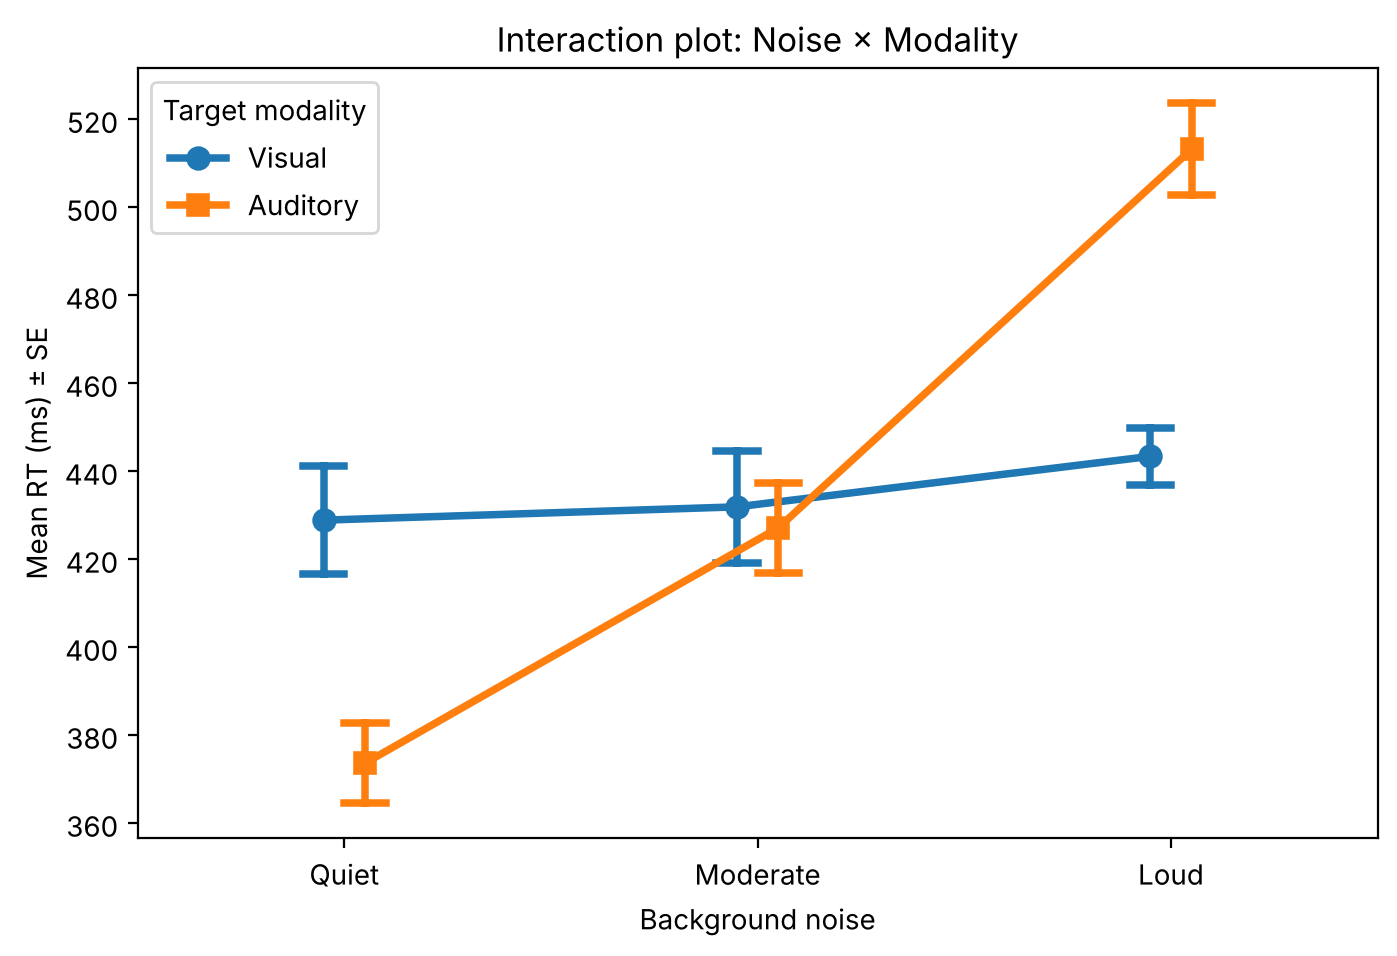

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Participants per cell:\n", pd.crosstab(df["Noise"], df["Modality"]).loc[noise_order], "\n")

cell_stats = (df.groupby(["Modality", "Noise"])["RT_ms"].agg(["mean", "std", "count"])
                .reindex(noise_order, level="Noise"))
print("Cell means:\n", cell_stats.round(1), "\n")
print("Marginal means Noise:\n", df.groupby("Noise")["RT_ms"].mean().loc[noise_order].round(1), "\n")
print("Marginal means Modality:\n", df.groupby("Modality")["RT_ms"].mean().round(1))
print("\nGrand mean:", round(df["RT_ms"].mean(), 1))

plt.figure(figsize=(8, 5))
sns.pointplot(x="Noise", y="RT_ms", hue="Modality", data=df, order=noise_order,
              dodge=0.1, markers=["o", "s"], capsize=0.1, errorbar="se")
plt.title("Interaction plot: Noise × Modality")
plt.ylabel("Mean RT (ms) ± SE")
plt.xlabel("Background noise")
plt.legend(title="Target modality")
plt.show()

**Answer**

1. Balanced: 8 participants in each of the 6 cells.
2. Cell and marginal means (ms):

| | Quiet | Moderate | Loud | Modality mean |
|---|---:|---:|---:|---:|
| **Visual** | 428.9 (SD 34.8) | 431.9 (SD 36.0) | 443.4 (SD 18.5) | 434.7 |
| **Auditory** | 373.6 (SD 25.7) | 427.1 (SD 29.1) | 513.2 (SD 29.6) | 438.0 |
| **Noise mean** | 401.2 | 429.5 | 478.3 | 436.3 |

4. The visual line is almost flat; the auditory line rises steeply with noise. The lines **cross**: auditory detection is faster than visual in quiet, similar at moderate noise and much slower in loud noise. Expectation: significant interaction, significant main effect of Noise (driven by the auditory line), probably no main effect of Modality.
5. The Modality marginal means are almost identical (434.7 vs 438.0 ms). Looking only at them, you would conclude that modality does not matter, which is wrong: the modality effect is **large but opposite** in quiet vs loud conditions, and it cancels out when averaged over noise levels.

#### 3.2 Check the assumptions

1. Test normality **within each of the 6 cells** (Shapiro–Wilk). Hint: create a `Cell` column combining both factors.
2. Test homogeneity of variances across the 6 cells (Levene).
3. Which other assumption must hold, and which design property is recommended for a two-way ANOVA? Are both satisfied?

In [ ]:
import pingouin as pg

# TODO 1: Cell column + Shapiro-Wilk per cell

# TODO 2: Levene across cells

**Solution**

In [6]:
import pingouin as pg

df["Cell"] = df["Noise"] + "_" + df["Modality"]
print("Shapiro-Wilk per cell:\n", pg.normality(data=df, dv="RT_ms", group="Cell").round(3))
print("\nLevene across cells:\n", pg.homoscedasticity(data=df, dv="RT_ms", group="Cell").round(3))

Shapiro-Wilk per cell:
                        W   pval  normal
Cell                                   
Quiet_Visual       0.930  0.514    True
Moderate_Auditory  0.889  0.230    True
Loud_Visual        0.887  0.218    True
Moderate_Visual    0.979  0.960    True
Loud_Auditory      0.899  0.282    True
Quiet_Auditory     0.882  0.196    True

Levene across cells:
             W   pval  equal_var
levene  0.586  0.711       True


**Answer**

1. All six Shapiro–Wilk p-values are > .05 (smallest $p = .196$), so normality is not rejected in any cell.
2. Levene: $W = 0.59$, $p = .711$, so equal variances are not rejected.
3. **Independence of observations** must be ensured by the design (each participant contributes one value to one cell). A **balanced design** (equal $n$ per cell) is recommended for two-way ANOVA; here every cell has $n = 8$. All assumptions are met.

#### 3.3 Run the two-way ANOVA

1. Write down the three null hypotheses.
2. Run the two-way between-subjects ANOVA with `pg.anova(dv, between=[...], data, detailed=True)`. Which effects are significant? Report each in the format $F(df_{effect}, df_E) = \dots, p = \dots$.
3. Verify the F-value for the interaction from the SS and df columns.
4. pingouin reports **partial** eta squared (`np2` $= SS_{effect} / (SS_{effect} + SS_E)$). Compute the **classical** $\eta^2 = SS_{effect} / SS_T$ for each effect and compare. Why are they different in a two-way design but identical in a one-way design?

In [ ]:
# TODO 1: two-way ANOVA

# TODO 2: verify F for the interaction (MS_interaction / MS_error)

# TODO 3: classical eta squared vs partial eta squared

**Solution**

In [8]:
aov2 = pg.anova(data=df, dv="RT_ms", between=["Noise", "Modality"], detailed=True)
print(aov2.round(4))

ss = aov2.set_index("Source")["SS"]
dof = aov2.set_index("Source")["DF"]
ms_error = ss["Residual"] / dof["Residual"]
F_int = (ss["Noise * Modality"] / dof["Noise * Modality"]) / ms_error
print(f"\nMS_error = {ms_error:.2f}; F_interaction = {F_int:.2f}")

ss_total = ((df["RT_ms"] - df["RT_ms"].mean()) ** 2).sum()
effects = ["Noise", "Modality", "Noise * Modality"]
eta = pd.DataFrame({
    "eta2 (SS_effect / SS_T)": ss[effects] / ss_total,
    "partial eta2 (SS_effect / (SS_effect + SS_E))": ss[effects] / (ss[effects] + ss["Residual"]),
})
print(f"\nSS_total = {ss_total:.1f} (sum of SS column = {ss.sum():.1f})")
print(eta.round(3))

             Source          SS  DF          MS        F   p_unc     np2
0             Noise  48583.4717   2  24291.7358  27.8419  0.0000  0.5700
1          Modality    127.4008   1    127.4008   0.1460  0.7043  0.0035
2  Noise * Modality  31662.2117   2  15831.1058  18.1447  0.0000  0.4635
3          Residual  36644.5750  42    872.4899      NaN     NaN     NaN

MS_error = 872.49; F_interaction = 18.14

SS_total = 117017.7 (sum of SS column = 117017.7)
                  eta2 (SS_effect / SS_T)  \
Source                                      
Noise                               0.415   
Modality                            0.001   
Noise * Modality                    0.271   

                  partial eta2 (SS_effect / (SS_effect + SS_E))  
Source                                                           
Noise                                                     0.570  
Modality                                                  0.003  
Noise * Modality                                    

**Answer**

1. Null hypotheses:
   - $H_0$(Noise): $\mu_{Quiet} = \mu_{Moderate} = \mu_{Loud}$
   - $H_0$(Modality): $\mu_{Visual} = \mu_{Auditory}$
   - $H_0$(Noise × Modality): no interaction, i.e. the effect of noise is the same for both modalities
2. Results ($df_E = 42$):
   - **Noise:** $F(2, 42) = 27.84$, $p < .001$, significant
   - **Modality:** $F(1, 42) = 0.15$, $p = .704$, **not significant**
   - **Noise × Modality:** $F(2, 42) = 18.14$, $p < .001$, significant
3. $MS_{A \times B} = 31662.2 / 2 = 15831.1$; $MS_E = 36644.6 / 42 = 872.5$; $F = 15831.1 / 872.5 = 18.14$ ✓
4. Effect sizes:

| Effect | $\eta^2$ | partial $\eta^2$ |
|---|---:|---:|
| Noise | .415 | .570 |
| Modality | .001 | .003 |
| Noise × Modality | .271 | .464 |

   Classical $\eta^2$ divides by the **total** SS, which in a two-way design also contains the other effects; partial $\eta^2$ removes the other effects from the denominator, so it is always ≥ $\eta^2$. In a one-way design $SS_T = SS_{effect} + SS_E$, so both are identical. Always state which one you report.

#### 3.4 Partition the variance yourself

Compute $SS_{Noise}$, $SS_{Modality}$, $SS_{Noise \times Modality}$ and $SS_E$ directly from the formulas with `pandas`, and check that
$SS_T = SS_A + SS_B + SS_{AB} + SS_E$ and that your values match the pingouin table.

*Hint:* `groupby(...).transform("mean")` gives every row the mean of its group, which makes $SS_E = \sum (X - \bar X_{cell})^2$ a one-liner.

In [ ]:
# TODO 1: grand mean, marginal means (with counts) for Noise and Modality

# TODO 2: SS_A and SS_B

# TODO 3: cell means and SS_AB

# TODO 4: SS_E (directly) and SS_T; check the decomposition

**Solution**

In [10]:
gm = df["RT_ms"].mean()

a = df.groupby("Noise")["RT_ms"].agg(["mean", "count"])
b = df.groupby("Modality")["RT_ms"].agg(["mean", "count"])
ss_a = (a["count"] * (a["mean"] - gm) ** 2).sum()
ss_b = (b["count"] * (b["mean"] - gm) ** 2).sum()

cells = df.groupby(["Noise", "Modality"])["RT_ms"].agg(["mean", "count"]).reset_index()
cells["mean_A"] = cells["Noise"].map(a["mean"])
cells["mean_B"] = cells["Modality"].map(b["mean"])
ss_ab = (cells["count"] * (cells["mean"] - cells["mean_A"] - cells["mean_B"] + gm) ** 2).sum()

cell_mean_per_row = df.groupby(["Noise", "Modality"])["RT_ms"].transform("mean")
ss_e = ((df["RT_ms"] - cell_mean_per_row) ** 2).sum()
ss_t = ((df["RT_ms"] - gm) ** 2).sum()

print(f"SS_Noise       = {ss_a:10.1f}")
print(f"SS_Modality    = {ss_b:10.1f}")
print(f"SS_Interaction = {ss_ab:10.1f}")
print(f"SS_Error       = {ss_e:10.1f}")
print(f"Sum            = {ss_a + ss_b + ss_ab + ss_e:10.1f}")
print(f"SS_Total       = {ss_t:10.1f}")

SS_Noise       =    48583.5
SS_Modality    =      127.4
SS_Interaction =    31662.2
SS_Error       =    36644.6
Sum            =   117017.7
SS_Total       =   117017.7


**Answer**

$SS_{Noise} = 48583.5$, $SS_{Modality} = 127.4$, $SS_{Noise \times Modality} = 31662.2$, $SS_E = 36644.6$. Their sum equals $SS_T = 117017.7$, and all values match pingouin. Note how small $SS_{Modality}$ is: the two modality marginal means are nearly equal, even though modality matters a lot within each noise level, and that variability ends up in $SS_{Noise \times Modality}$.

#### 3.5 Interpreting the interaction: simple effects

A colleague reads the ANOVA table and concludes:

> (a) "Background noise slows down target detection."
> (b) "Target modality has no effect on reaction time."

**Questions**
1. Evaluate both statements. Why should you examine the interaction **before** interpreting the main effects?
2. Follow up the interaction with **simple effects**:
   - a one-way ANOVA of Noise **separately** for the visual and the auditory group, with Tukey HSD where the effect is significant;
   - an independent-samples t-test of Visual vs Auditory **at each noise level**, Bonferroni-corrected for 3 tests ($\alpha = .05/3$).
3. Compare with Tukey HSD on the **main effect** of Noise (averaging over modality). Which conclusion about Quiet vs Moderate changes?

In [ ]:
from scipy import stats

# TODO 1: one-way ANOVA of Noise within each modality (+ Tukey where significant)

# TODO 2: Visual vs Auditory t-test at each noise level, compare p with .05/3

# TODO 3: Tukey on the Noise main effect (all data)

**Solution**

In [12]:
from scipy import stats

for mod in ["Visual", "Auditory"]:
    sub = df[df["Modality"] == mod]
    print(f"--- Simple effect of Noise for {mod} targets")
    print(pg.anova(data=sub, dv="RT_ms", between="Noise", detailed=True).round(4))
    print(pg.pairwise_tukey(data=sub, dv="RT_ms", between="Noise")[["A", "B", "diff", "p_tukey"]].round(4), "\n")

alpha_bonf = 0.05 / 3
print(f"--- Simple effect of Modality at each noise level (Bonferroni alpha = {alpha_bonf:.4f})")
for noise in noise_order:
    sub = df[df["Noise"] == noise]
    t, p = stats.ttest_ind(sub.loc[sub["Modality"] == "Visual", "RT_ms"],
                           sub.loc[sub["Modality"] == "Auditory", "RT_ms"])
    print(f"{noise:9s}: t(14) = {t:6.2f}, p = {p:.4f}, significant: {p < alpha_bonf}")

print("\n--- Tukey on the main effect of Noise (averaged over modality)")
print(pg.pairwise_tukey(data=df, dv="RT_ms", between="Noise")[["A", "B", "diff", "p_tukey"]].round(4))

--- Simple effect of Noise for Visual targets
   Source          SS  DF        MS      F   p_unc     np2
0   Noise    936.2033   2  468.1017  0.493  0.6177  0.0448
1  Within  19941.1900  21  949.5805    NaN     NaN     NaN
          A         B    diff  p_tukey
0      Loud  Moderate  11.475    0.740
1      Loud     Quiet  14.500    0.621
2  Moderate     Quiet   3.025    0.979 

--- Simple effect of Noise for Auditory targets
   Source         SS  DF          MS        F  p_unc    np2
0   Noise  79309.480   2  39654.7400  49.8551    0.0  0.826
1  Within  16703.385  21    795.3993      NaN    NaN    NaN
          A         B    diff  p_tukey
0      Loud  Moderate   86.05   0.0000
1      Loud     Quiet  139.55   0.0000
2  Moderate     Quiet   53.50   0.0029 

--- Simple effect of Modality at each noise level (Bonferroni alpha = 0.0167)
Quiet    : t(14) =   3.61, p = 0.0028, significant: True
Moderate : t(14) =   0.29, p = 0.7747, significant: False
Loud     : t(14) =  -5.65, p = 0.0001, s

**Answer**

1. Both statements are misleading, because the interaction is significant:
   - (a) holds only for **auditory** targets. For visual targets, noise has no significant effect. The Noise main effect is an average over two very different patterns.
   - (b) is wrong: modality has a **large** effect at both extreme noise levels (quiet and loud), but in **opposite directions**, which cancel out in the marginal means.
   - Always check the interaction first: if it is significant, main effects can hide or misrepresent how one factor's effect depends on the other.
2. Simple effects:
   - **Noise within Visual:** $F(2, 21) = 0.49$, $p = .618$, no effect of acoustic noise on visual detection.
   - **Noise within Auditory:** $F(2, 21) = 49.86$, $p < .001$; Tukey: all pairs differ (Quiet < Moderate $p = .003$; Moderate < Loud and Quiet < Loud, both $p < .001$).
   - **Modality at each noise level** (Bonferroni $\alpha = .0167$): Quiet $t(14) = 3.61$, $p = .003$ (auditory **faster**); Moderate $t(14) = 0.29$, $p = .775$ (no difference); Loud $t(14) = -5.65$, $p < .001$ (auditory **slower**).
3. On the averaged Noise main effect, Tukey finds **no** difference between Quiet and Moderate ($p = .112$), but within the auditory group this difference is clearly significant ($p = .003$). Averaging over the visual group, where noise does nothing, dilutes the effect.

#### 3.6 Write the results

Write a short results paragraph (4–6 sentences) for this experiment, as you would in a lab report. Then compare it with the checklist below.

**Answer**

**A complete paragraph contains:**
- Design and test: 3 (Noise) × 2 (Modality) between-subjects ANOVA, $N = 48$, $n = 8$ per cell
- Assumption checks: Shapiro–Wilk per cell all $p > .19$, Levene $p = .711$
- All three effects with $F(df_{effect}, df_E)$, $p$ and an effect size, stating which $\eta^2$ is reported
- Interaction interpreted **first**, with the direction of the simple effects
- Main effects qualified in light of the interaction
- Interpretation in context (acoustic masking affects auditory, not visual, detection)

**Example:** A 3 × 2 between-subjects ANOVA revealed a significant Noise × Modality interaction, $F(2, 42) = 18.14$, $p < .001$, $\eta_p^2 = .46$, and a significant main effect of Noise, $F(2, 42) = 27.84$, $p < .001$, $\eta_p^2 = .57$, but no main effect of Modality, $F(1, 42) = 0.15$, $p = .704$. Simple-effects analyses showed that noise slowed auditory detection (Quiet 374 ms < Moderate 427 ms < Loud 513 ms, all Tukey $p \leq .003$) but did not affect visual detection, $F(2, 21) = 0.49$, $p = .618$. Auditory targets were detected faster than visual targets in quiet ($p = .003$) but slower in loud noise ($p < .001$), so the absent main effect of Modality reflects opposite effects that cancel out. Assumptions of normality (Shapiro–Wilk, all $p > .19$) and equal variances (Levene, $p = .711$) were met.

### Optional Follow-Up Thought
Suppose every participant had been tested with **both** modalities and **all three** noise levels. How would the data table change (one row per participant? per condition?), and how would the interaction plot look if each participant contributed a point to all 6 conditions? Which source of variance could then be separated from the error term?
Next week we'll take this step with **repeated-measures ANOVA**.